# Industrial Predictive Maintenance

## Notebook 02: Data Validation and Missingness Analysis

### Objective

Assess data quality, validate data integrity, and
identify missingness patterns without modifying
the original datasets.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [3]:
DATA_PATH = Path("../data/raw")

readings = pd.read_csv(DATA_PATH / "readings.csv")
units = pd.read_csv(DATA_PATH / "units.csv")
ground_truth = pd.read_csv(DATA_PATH / "ground_truth.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


## 3. Data Validation

### 3.1 Primary Key Validation

Verify that the primary keys are unique
and contain no missing values.

- units: unit_id
- readings: unit_id and cycle
- ground_truth: unit_id and cycle



In [4]:
print("Units duplicate keys:",
      units.duplicated(subset=["unit_id"]).sum())

print("Readings duplicate keys:",
      readings.duplicated(subset=["unit_id", "cycle"]).sum())

print("Ground truth duplicate keys:",
      ground_truth.duplicated(subset=["unit_id", "cycle"]).sum())

Units duplicate keys: 0
Readings duplicate keys: 0
Ground truth duplicate keys: 0


In [5]:
print("Units missing keys:",
      units[["unit_id"]].isnull().sum().sum())

print("Readings missing keys:",
      readings[["unit_id", "cycle"]].isnull().sum().sum())

print("Ground truth missing keys:",
      ground_truth[["unit_id", "cycle"]].isnull().sum().sum())

Units missing keys: 0
Readings missing keys: 0
Ground truth missing keys: 0


### 3.2 Foreign Key Validation

Verify that every machine identifier in the readings
and ground truth tables exists in the units table.

In [6]:
invalid_readings = readings[
    ~readings["unit_id"].isin(units["unit_id"])
]

invalid_ground_truth = ground_truth[
    ~ground_truth["unit_id"].isin(units["unit_id"])
]

print("Invalid foreign keys in readings:",
      len(invalid_readings))

print("Invalid foreign keys in ground truth:",
      len(invalid_ground_truth))

Invalid foreign keys in readings: 0
Invalid foreign keys in ground truth: 0


### 3.3 Cross-table Consistency

Verify that the readings and ground truth tables
contain matching machine-cycle combinations.

In [7]:
consistency_check = pd.merge(
    readings[["unit_id", "cycle"]],
    ground_truth[["unit_id", "cycle"]],
    on=["unit_id", "cycle"],
    how="outer",
    indicator=True
)

display(consistency_check["_merge"].value_counts())

_merge
both          23118
left_only         0
right_only        0
Name: count, dtype: int64

### 3.4 Cycle Continuity



In [8]:
sorted_readings = readings.sort_values(
    ["unit_id", "cycle"]
)

cycle_diff = sorted_readings.groupby("unit_id")["cycle"].diff()

cycle_issues = sorted_readings[
    cycle_diff.notna() & (cycle_diff != 1)
]

print("Cycle continuity issues:", len(cycle_issues))

display(cycle_issues)

Cycle continuity issues: 0


,unit_id,cycle,rul_cycles,machine_failure,failure_mode,tool_wear_min,vibration_mm_s,torque_nm,process_temperature_k,air_temperature_k,rotational_speed_rpm,control_type,split


### 3.5 RUL Consistency

Verify that the remaining useful life decreases
by one cycle at each consecutive observation
and reaches zero at the final cycle.

In [9]:
rul_diff = sorted_readings.groupby(
    "unit_id"
)["rul_cycles"].diff()

rul_issues = sorted_readings[
    rul_diff.notna() & (rul_diff != -1)
]

print("RUL progression issues:", len(rul_issues))

display(rul_issues)

RUL progression issues: 0


,unit_id,cycle,rul_cycles,machine_failure,failure_mode,tool_wear_min,vibration_mm_s,torque_nm,process_temperature_k,air_temperature_k,rotational_speed_rpm,control_type,split


In [10]:
last_cycles = sorted_readings.groupby("unit_id").tail(1)

invalid_final_rul = last_cycles[
    last_cycles["rul_cycles"] != 0
]

print("Invalid final RUL values:", len(invalid_final_rul))

display(invalid_final_rul)

Invalid final RUL values: 0


,unit_id,cycle,rul_cycles,machine_failure,failure_mode,tool_wear_min,vibration_mm_s,torque_nm,process_temperature_k,air_temperature_k,rotational_speed_rpm,control_type,split


### 3.6 Failure Flag Consistency

Verify that machine failure is recorded only
at the final operating cycle of each machine.

In [11]:
expected_failure = (
    sorted_readings["cycle"] ==
    sorted_readings.groupby("unit_id")["cycle"].transform("max")
).astype(int)

failure_issues = sorted_readings[
    sorted_readings["machine_failure"] != expected_failure
]

print("Failure flag inconsistencies:", len(failure_issues))

display(failure_issues)

Failure flag inconsistencies: 0


,unit_id,cycle,rul_cycles,machine_failure,failure_mode,tool_wear_min,vibration_mm_s,torque_nm,process_temperature_k,air_temperature_k,rotational_speed_rpm,control_type,split


### 3.7 Failure Mode Consistency

Verify that the recorded failure mode matches
the final failure mode defined in the units table.

In [12]:
failure_records = readings[
    readings["machine_failure"] == 1
]

failure_check = failure_records.merge(
    units[["unit_id", "failure_mode"]],
    on="unit_id",
    suffixes=("_readings", "_units")
)

mode_issues = failure_check[
    failure_check["failure_mode_readings"] !=
    failure_check["failure_mode_units"]
]

print("Failure mode inconsistencies:", len(mode_issues))

display(mode_issues)

Failure mode inconsistencies: 0


,unit_id,cycle,rul_cycles,machine_failure,failure_mode_readings,tool_wear_min,vibration_mm_s,torque_nm,process_temperature_k,air_temperature_k,rotational_speed_rpm,control_type,split,failure_mode_units


### 3.8 Sensor Range Validation

Identify physically invalid sensor measurements
without modifying or removing any observations.

In [13]:
sensor_checks = {
    "tool_wear_min": readings["tool_wear_min"] < 0,
    "vibration_mm_s": readings["vibration_mm_s"] < 0,
    "torque_nm": readings["torque_nm"] < 0,
    "process_temperature_k": readings["process_temperature_k"] <= 0,
    "air_temperature_k": readings["air_temperature_k"] <= 0,
    "rotational_speed_rpm": readings["rotational_speed_rpm"] <= 0
}

sensor_validation = pd.DataFrame({
    "Sensor": sensor_checks.keys(),
    "Invalid Values": [
        condition.sum()
        for condition in sensor_checks.values()
    ]
})

display(sensor_validation)

,Sensor,Invalid Values
0,tool_wear_min,25
1,vibration_mm_s,0
2,torque_nm,0
3,process_temperature_k,0
4,air_temperature_k,0
5,rotational_speed_rpm,0


In [14]:
negative_tool_wear = readings[
    readings["tool_wear_min"] < 0
]

print("Negative tool wear values:", len(negative_tool_wear))

display(negative_tool_wear)

Negative tool wear values: 25


,unit_id,cycle,rul_cycles,machine_failure,failure_mode,tool_wear_min,vibration_mm_s,torque_nm,process_temperature_k,air_temperature_k,rotational_speed_rpm,control_type,split
0,U0001,1,275,0,none,-1.0,0.864,NaN,310.32,299.88,1573.0,B,train
813,U0004,1,268,0,none,-1.0,NaN,43.32,310.48,300.37,1605.0,A,train
814,U0004,2,267,0,none,-1.0,0.891,NaN,310.33,299.65,1499.0,B,train
1082,U0005,1,281,0,none,-1.0,0.790,NaN,310.85,300.21,1625.0,B,train
2116,U0010,1,246,0,none,-1.0,NaN,40.31,310.19,299.57,1564.0,A,train
3417,U0015,1,227,0,none,-1.0,0.803,39.44,310.78,NaN,1565.0,C,train
4047,U0018,1,272,0,none,-1.0,NaN,38.60,309.74,300.47,1539.0,A,train
4788,U0021,1,307,0,none,-1.0,0.811,39.37,309.86,NaN,1574.0,C,train
6275,U0027,1,210,0,none,-1.0,0.815,36.18,310.59,NaN,1489.0,C,train
6486,U0028,1,212,0,none,-1.0,0.931,40.59,309.98,NaN,1518.0,C,train


## 4. Missingness Analysis

### 4.1 Missing Values Visualization

Visualize the percentage and distribution of missing
sensor measurements in the readings dataset.

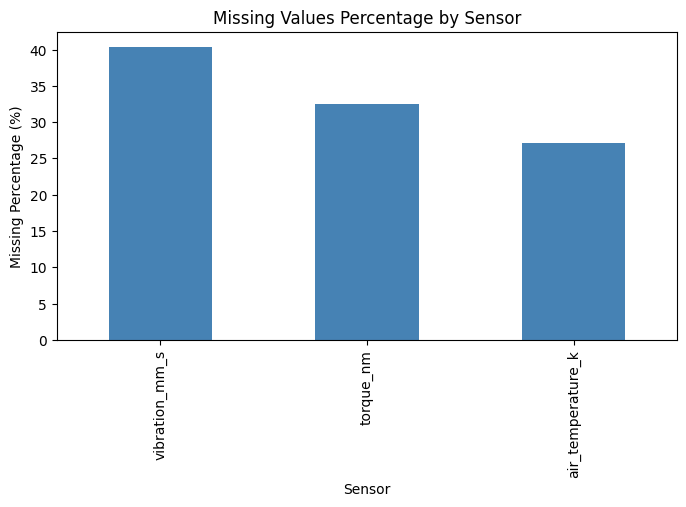

In [17]:
missing_percentage = readings.isnull().mean() * 100

missing_percentage = missing_percentage[
    missing_percentage > 0
]

plt.figure(figsize=(8, 4))

missing_percentage.plot(kind="bar", color="steelblue")

plt.title("Missing Values Percentage by Sensor")
plt.xlabel("Sensor")
plt.ylabel("Missing Percentage (%)")


plt.show()

### 4.2 Missingness by Control Type

Investigate whether missing sensor measurements
are associated with the machine control type.

In [19]:
missing_sensors = [
    "vibration_mm_s",
    "torque_nm",
    "air_temperature_k"
]

missing_by_control = readings.groupby(
    "control_type"
)[missing_sensors].apply(
    lambda x: x.isnull().mean() * 100
)

display(missing_by_control.round(2))

,vibration_mm_s,torque_nm,air_temperature_k
control_type,,,
A,100.0,0.0,0.0
B,0.0,100.0,0.0
C,0.0,0.0,100.0


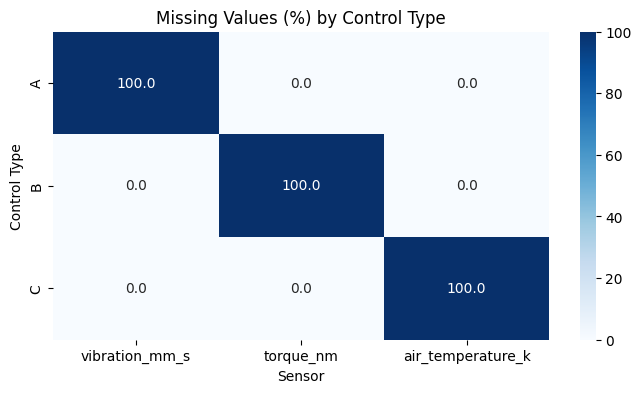

In [21]:
plt.figure(figsize=(8, 4))

sns.heatmap(
    missing_by_control,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100
)

plt.title("Missing Values (%) by Control Type")
plt.xlabel("Sensor")
plt.ylabel("Control Type")
plt.show()

### 4.3 Control Type Variation Within Machines

Determine whether the control type remains constant
or changes within each machine.

In [22]:
control_types_per_machine = readings.groupby(
    "unit_id"
)["control_type"].nunique()

display(control_types_per_machine.value_counts())

control_type
3    100
Name: count, dtype: int64

### 4.4 Structural Missingness Validation

Verify whether missing sensor measurements follow
the expected control-type missingness pattern.

In [24]:
expected_patterns = {
    "vibration_mm_s": "A",
    "torque_nm": "B",
    "air_temperature_k": "C"
}

for sensor, control in expected_patterns.items():

    actual_missing = readings[sensor].isnull()

    expected_missing = readings["control_type"] == control

    unexpected_missing = (
        actual_missing & ~expected_missing
    ).sum()

    unexpected_present = (
        ~actual_missing & expected_missing
    ).sum()

    print(f"\nSensor: {sensor}")
    print("Unexpected missing values:", unexpected_missing)
    print("Unexpected available values:", unexpected_present)


Sensor: vibration_mm_s
Unexpected missing values: 0
Unexpected available values: 0

Sensor: torque_nm
Unexpected missing values: 0
Unexpected available values: 0

Sensor: air_temperature_k
Unexpected missing values: 0
Unexpected available values: 0


### 4.5 Missingness Mechanism Analysis

- MCAR: Not supported.
- MAR: Consistent with the observed pattern.
- MNAR: No supporting evidence identified.

Missingness is structurally associated with
control_type, an observed variable.
The observed data alone cannot rule out MNAR.


## 5. Final Findings

- All primary and foreign key checks passed.
- All 23,118 machine-cycle records match across tables.
- Cycle, RUL, and failure consistency checks passed.
- 25 negative tool wear values were detected.
- Missingness follows the control-type pattern.
- All 100 machines use all three control types.
- No unexpected missing values were detected in the checked sensors.

The original datasets remain unchanged.